# Ödev 1 — Veri Temizleme: İş İlanları (`Is_ilanlari.csv`)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Klasör yolları (notebook, notebooks/ klasöründen çalıştırılır)
RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIGURES = Path("../figures")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
df_raw = pd.read_csv(RAW / "Is_ilanlari.csv", sep=";") # Ayraç virgül değil, noktalı virgül (;)
df = df_raw.copy()  # df_raw, temizlik öncesi/sonrası karşılaştırma için değişmeden kalır
df.head()

,Job Title,Salary Estimate,Job Description,Rating,Company Name,Location,Headquarters,Size,Type of ownership,Industry,Sector,Revenue,min_salary,max_salary,avg_salary,job_state,same_state,company_age,python,excel,hadoop,spark,aws,tableau,big_data,job_simp,seniority
0,Sr Data Scientist,137-171,Description\n\nThe Senior Data Scientist is re...,31,Healthfirst,"New York, NY","New York, NY",1001 to 5000 employees,Nonprofit Organization,Insurance Carriers,Insurance,Unknown / Non-Applicable,137,171,154,NY,1,27,0,0,0,0,1,0,0,data scientist,senior
1,Data Scientist,137-171,"Secure our Nation, Ignite your Future\n\nJoin ...",42,ManTech,"Chantilly, VA","Herndon, VA",5001 to 10000 employees,Company - Public,Research & Development,Business Services,$1 to $2 billion (USD),137,171,154,VA,0,52,0,0,1,0,0,0,1,data scientist,na
2,Data Scientist,137-171,Overview\n\n\nAnalysis Group is one of the lar...,38,Analysis Group,"Boston, MA","Boston, MA",1001 to 5000 employees,Private Practice / Firm,Consulting,Business Services,$100 to $500 million (USD),137,171,154,MA,1,39,1,1,0,0,1,0,0,data scientist,na
3,Data Scientist,137-171,JOB DESCRIPTION:\n\nDo you have a passion for ...,35,INFICON,"Newton, MA","Bad Ragaz, Switzerland",501 to 1000 employees,Company - Public,Electrical & Electronic Manufacturing,Manufacturing,$100 to $500 million (USD),137,171,154,MA,0,20,1,1,0,0,1,0,0,data scientist,na
4,Data Scientist,137-171,Data Scientist\nAffinity Solutions / Marketing...,29,Affinity Solutions,"New York, NY","New York, NY",51 to 200 employees,Company - Private,Advertising & Marketing,Business Services,Unknown / Non-Applicable,137,171,154,NY,1,22,1,1,0,0,0,0,0,data scientist,na


## 1. Veriyi Keşfetme ve İlk Analiz

In [3]:
# Ham veri: bu bölümde hiç değiştirilmez, tüm tespitler bunun üzerinde yapılır
ham = df_raw
print(f"Satır: {ham.shape[0]}, sütun: {ham.shape[1]}")
ham.info()

Satır: 660, sütun: 27
<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Job Title          660 non-null    str  
 1   Salary Estimate    660 non-null    str  
 2   Job Description    660 non-null    str  
 3   Rating             660 non-null    int64
 4   Company Name       660 non-null    str  
 5   Location           660 non-null    str  
 6   Headquarters       660 non-null    str  
 7   Size               660 non-null    str  
 8   Type of ownership  660 non-null    str  
 9   Industry           660 non-null    str  
 10  Sector             660 non-null    str  
 11  Revenue            660 non-null    str  
 12  min_salary         660 non-null    int64
 13  max_salary         660 non-null    int64
 14  avg_salary         660 non-null    int64
 15  job_state          660 non-null    str  
 16  same_state         660 non-null    int64
 17  compa

In [4]:
# Tespit fonksiyonları: veriyi sadece okur, hiçbir şeyi değiştirmez
metin_sutunlari = ham.select_dtypes(include=["object", "string"]).columns

# Eksik anlamına gelen yazılar (harften bağımsız karşılaştırılır).
# "-1" ve "unknown", Glassdoor kaynaklı bu veride "bilgi yok" için kullanılan yer tutuculardır.
EKSIK_IFADELER = {"na", "n/a", "#n/a", "nan", "null", "none", "nil", "unknown", "unknown / non-applicable",
                  "missing", "undefined", "bilinmiyor", "yok", "-1"}


def bosluk_raporu(veri):
    """Her metin sütununda başında / sonunda boşluk olan hücre sayısı."""
    satirlar = []
    for sutun in metin_sutunlari:
        degerler = veri[sutun].dropna().astype(str)
        satirlar.append({
            "Sütun": sutun,
            "Baştaki boşluk": (degerler != degerler.str.lstrip()).sum(),
            "Sondaki boşluk": (degerler != degerler.str.rstrip()).sum(),
        })
    return pd.DataFrame(satirlar)


def harf_raporu(veri):
    """Yalnızca büyük / küçük harf farkı yüzünden ayrı görünen değerler."""
    satirlar = []
    for sutun in metin_sutunlari:
        degerler = veri[sutun].dropna().astype(str)
        for anahtar, grup in degerler.groupby(degerler.str.lower()):
            yazimlar = grup.value_counts()
            if len(yazimlar) > 1:
                satirlar.append({
                    "Sütun": sutun,
                    "Değer": anahtar,
                    "Yazım biçimleri": ", ".join(f"{y!r} ({n})" for y, n in yazimlar.items()),
                    "Kayıt sayısı": len(grup),
                })
    return pd.DataFrame(satirlar, columns=["Sütun", "Değer", "Yazım biçimleri", "Kayıt sayısı"])


def yazim_anahtari(seri):
    """Harf, boşluk ve noktalama farkını yok sayan karşılaştırma anahtarı.
    'Mc Lean, VA' ile 'McLean, VA' ya da 'Sr. Data Analyst' ile 'Sr Data Analyst' aynı anahtara düşer."""
    return seri.str.lower().str.replace(r"[^a-z0-9]", "", regex=True)


def yazim_varyanti_raporu(veri, sutunlar):
    """Aynı anahtara sahip ama birden fazla yazımı olan değerler (harf raporunun daha geniş hali)."""
    satirlar = []
    for sutun in sutunlar:
        degerler = veri[sutun].dropna().astype(str)
        for anahtar, grup in degerler.groupby(yazim_anahtari(degerler)):
            yazimlar = grup.value_counts()
            if len(yazimlar) > 1:
                satirlar.append({
                    "Sütun": sutun,
                    "Yazım biçimleri": ", ".join(f"{y!r} ({n})" for y, n in yazimlar.items()),
                    "Kayıt sayısı": len(grup),
                })
    return pd.DataFrame(satirlar, columns=["Sütun", "Yazım biçimleri", "Kayıt sayısı"])


def metin_eksik_kurallari(degerler):
    """Metin değerleri için gizli eksik kuralları: {neden: hangi değerlerin uyduğu}."""
    normal = degerler.str.strip().str.lower()
    return {
        "eksik ifadesi": normal.isin(EKSIK_IFADELER),
        "harf / rakam yok": ~normal.str.contains(r"[^\W_]"),  # "", "?", "-" gibi
    }


def sayisal_eksik_kurallari(degerler):
    """Sayısal değerler için şüpheli değer kuralı: sıfır veya negatif."""
    return {"sıfır veya negatif": degerler <= 0}


def gizli_eksik_raporu(veri):
    """Null görünmeyen ama eksik anlamına gelebilecek değerler ve kaç kez geçtikleri.
    0/1 olan işaret sütunlarında (python, excel, ...) 0 normal bir değerdir, bu yüzden sayısal kurallar onlara uygulanmaz."""
    kontroller = [(sutun, metin_eksik_kurallari, veri[sutun].dropna().astype(str)) for sutun in metin_sutunlari]
    ikili_degil = [s for s in veri.select_dtypes(include="number").columns if veri[s].nunique() > 2]
    kontroller += [(sutun, sayisal_eksik_kurallari, veri[sutun].dropna()) for sutun in ikili_degil]
    satirlar = []
    for sutun, kurallar, degerler in kontroller:
        for neden, maske in kurallar(degerler).items():
            for deger, sayi in degerler[maske].value_counts().items():
                satirlar.append({"Sütun": sutun, "Değer": repr(deger), "Neden": neden, "Kayıt sayısı": sayi})
    return pd.DataFrame(satirlar, columns=["Sütun", "Değer", "Neden", "Kayıt sayısı"])


def tutarlilik_raporu(veri):
    """Sütunlar arası tutarlılık kontrolleri: her kontrolün uyuşmayan satır sayısı."""
    maas = veri["Salary Estimate"].str.strip().str.split("-", expand=True).astype(int)
    konum_eyalet = veri["Location"].str.split(",").str[-1].str.strip().fillna("")
    sehir_ayni = veri["Location"].fillna("").str.strip() == veri["Headquarters"].fillna("").str.strip()
    return pd.Series({
        "Salary Estimate ile min/max_salary uyuşmuyor": ((maas[0] != veri["min_salary"]) | (maas[1] != veri["max_salary"])).sum(),
        "min_salary > max_salary": (veri["min_salary"] > veri["max_salary"]).sum(),
        "avg_salary, (min+max)//2'ye eşit değil": (veri["avg_salary"] != (veri["min_salary"] + veri["max_salary"]) // 2).sum(),
        "Location'daki eyalet ile job_state farklı": (konum_eyalet != veri["job_state"].fillna("").str.strip()).sum(),
        "same_state, (Location == Headquarters) ile uyuşmuyor": (veri["same_state"] != sehir_ayni.astype(int)).sum(),
    }, name="Uyuşmayan satır")

### 1.1 Tespit (ham veri)

In [5]:
# Başında / sonunda boşluk
bosluk_raporu(ham)

,Sütun,Baştaki boşluk,Sondaki boşluk
0,Job Title,0,0
1,Salary Estimate,0,641
2,Job Description,0,0
3,Company Name,0,0
4,Location,0,0
5,Headquarters,0,0
6,Size,0,0
7,Type of ownership,0,0
8,Industry,0,0
9,Sector,0,0


> **Boşluk:** `Salary Estimate` sütunundaki değerlerin neredeyse hepsinin sonunda (`'137-171 '`), `job_state` sütunundaki değerlerin neredeyse hepsinin başında (`' CA'`) fazladan boşluk var. Bu haliyle `'CA'` ile `' CA'` ayrı eyalet gibi görünür ve metinden sayı ayrıştırırken hata verir.

In [6]:
# Boşluklar yalnızca karşılaştırma için geçici olarak atılıyor; ham değişmiyor
harf_raporu(ham)

,Sütun,Değer,Yazım biçimleri,Kayıt sayısı


In [7]:
# Harf, boşluk ve noktalama farkını yok sayan geniş karşılaştırma (Job Description hariç, uzun metin)
yazim_varyanti_raporu(ham, [s for s in metin_sutunlari if s != "Job Description"])

,Sütun,Yazım biçimleri,Kayıt sayısı
0,Job Title,"'Data Scientist/Machine Learning' (2), 'Data S...",5
1,Job Title,"'Sr Data Analyst' (1), 'Sr. Data Analyst' (1)",2
2,Job Title,"'Sr Data Scientist' (2), 'Sr. Data Scientist' (2)",4
3,Headquarters,"'Mc Lean, VA' (13), 'McLean, VA' (4)",17


In [8]:
# Tamamı büyük harfle yazılmış unvanlar (harf_raporu bunları yakalamaz: yalnızca aynı değerin farklı harf yazımlarını arar)
buyuk_harf = ham.loc[ham["Job Title"].str.strip().str.isupper(), "Job Title"]
print(f"Tamamı büyük harf olan unvan: {len(buyuk_harf)} satır, {buyuk_harf.nunique()} farklı değer")
buyuk_harf.drop_duplicates().to_frame()

Tamamı büyük harf olan unvan: 7 satır, 4 farklı değer


,Job Title
148,ELISA RESEARCH SCIENTIST (CV-15)
207,ENGINEER - COMPUTER SCIENTIST - RESEARCH COMPU...
514,COMPUTER SCIENTIST - ENGINEER - RESEARCH COMPU...
533,COMPUTER SCIENTIST - ENGINEER - RESEARCH COMPU...


In [9]:
import re

# Büyük harfli unvanlardaki belirsiz kelimeler: ELISA bir kısaltma mı, OR bağlaç mı yoksa eyalet kodu (Oregon) mu?
# Anlamları, unvanın ait olduğu ilanın açıklamasında geçtikleri cümleden kontrol edilir.
for kelime, desen in {"ELISA": r"[^.]*\bELISA\b[^.]*\.", "OR": r"[^.]*San Antonio or [^.]*\."}.items():
    ilan = ham.loc[ham["Job Title"].str.isupper() & ham["Job Title"].str.contains(rf"\b{kelime}\b"), "Job Description"].iloc[0]
    print(f"{kelime:6s}: {re.search(desen, ilan).group(0).strip()}")

ELISA : As a result, Covaxx is quickly expanding to meet aggressive development and production goals, and is seeking to immediately hire 2 Research Scientists for the Company’s ELISA laboratory.
OR    : Work assignment is in San Antonio or Oklahoma City.


> **Yazım tutarsızlıkları:** Aynı değerin yalnızca harf farkıyla ikiye bölündüğü bir durum yok (`harf_raporu` boş), ama başka tutarsızlıklar var: `Job Title`'da `Sr` / `Sr.` yazımları (bir de `Senior` ile karışıyor), `Jr.` kısaltması ve `Data Scientist - Machine Learning` gibi ayraç farkları; ayrıca tamamı büyük harfle yazılmış unvanlar (yukarıda). Bu unvanlar düzeltilirken kelimeler tek tek ele alınmalı: `ELISA` bir kısaltma (açıklamada şirketin ELISA laboratuvarı geçiyor) ve `(CV-15)` rakam içeren bir pozisyon kodu, ikisi de olduğu gibi kalmalı; `OR` ise Oregon'un kısaltması değil, bağlaç (açıklamada "San Antonio or Oklahoma City"), küçük harfle yazılmalı. Diğer kelimeler sıradan kelimeler. `Headquarters`'ta `Mc Lean, VA` ile `McLean, VA` var; `Location` sütunu `McLean` yazımını kullanıyor, doğru yazım budur.

In [10]:
# Gizli eksikler: NaN görünmeyen ama eksik anlamına gelen değerler
gizli_eksik_raporu(ham)

,Sütun,Değer,Neden,Kayıt sayısı
0,Headquarters,'-1',eksik ifadesi,31
1,Size,'-1',eksik ifadesi,27
2,Size,'Unknown',eksik ifadesi,17
3,Type of ownership,'-1',eksik ifadesi,27
4,Type of ownership,'Unknown',eksik ifadesi,4
5,Industry,'-1',eksik ifadesi,71
6,Sector,'-1',eksik ifadesi,71
7,Revenue,'Unknown / Non-Applicable',eksik ifadesi,206
8,Revenue,'-1',eksik ifadesi,27
9,job_simp,'na',eksik ifadesi,68


> **Gizli eksikler:** Veride tek bir `NaN` yok, ama bütün eksikler yer tutucu olarak yazılmış: `-1` (`Headquarters`, `Size`, `Type of ownership`, `Industry`, `Sector`, `Revenue`, `company_age`), `Unknown` ve `Unknown / Non-Applicable` (`Size`, `Type of ownership`, `Revenue`), `Rating` sütununda `0` (geçerli puanlar 2,0'dan başlıyor). `Location = United States` / `job_state = US` değerleri ise eksik sayılmadı (aşağıda). `job_simp` ve `seniority` içindeki `na` değerleri ise farklı bir durum: bunlar eksik değil, “hiçbir kategoriye uymuyor” etiketi (1.2'de ele alınıyor).

In [11]:
# Yanlış ölçek: Rating tam sayı olarak saklanmış mı?
print("Rating (0 hariç) en küçük / en büyük:", ham.loc[ham["Rating"] > 0, "Rating"].min(), "/", ham["Rating"].max())
ham["Rating"].value_counts().sort_index().head(8)

Rating (0 hariç) en küçük / en büyük: 20 / 50


Rating
0     50
20     1
21     1
22     1
23     1
24     1
25     2
26     4
Name: count, dtype: int64

> **Yanlış veri tipi / ölçek — `Rating`:** Şirket puanı 5 üzerinden olmalı (ör. 3,1), ancak 31 gibi tam sayılar olarak saklanmış: yani 10 ile çarpılmış. 0 değeri ise eksik anlamına geliyor. `company_age` ve diğer sayısal sütunların tipleri doğru.

In [12]:
# Sütunlar arası tutarlılık
tutarlilik_raporu(ham)

Salary Estimate ile min/max_salary uyuşmuyor             0
min_salary > max_salary                                  0
avg_salary, (min+max)//2'ye eşit değil                   0
Location'daki eyalet ile job_state farklı               11
same_state, (Location == Headquarters) ile uyuşmuyor     0
Name: Uyuşmayan satır, dtype: int64

> **Tutarlılık:** `Salary Estimate` ile `min_salary` / `max_salary` her satırda uyuşuyor, `avg_salary` de her satırda (min+max)/2'nin aşağı yuvarlanmış hali (`//`). `Location`'daki eyalet ile `job_state` 11 satırda farklı: bunlar `Location = United States`, `job_state = US` olan ülke düzeyinde ilanlar. Eksik değil, bir bilgi taşıyorlar: ilan belirli bir şehre ya da eyalete bağlı değil (bu 11 ilandan 3'ünün açıklamasında remote / nationwide / anywhere geçiyor). Bu yüzden `NaN` yapılmadı ve bu uyuşmazlık kontrolde bilerek 11 olarak kalıyor. `same_state` adı yanıltıcı: aslında eyalet değil, şehir (`Location == Headquarters`) karşılaştırması. Veri bu şekilde üretilmiş, hata değil, bu yüzden değiştirilmiyor.

In [13]:
# Tekrar eden satırlar
tekrarlar = ham[ham.duplicated(keep=False)]
print(f"Tamamen aynı satır: {ham.duplicated().sum()} (toplam {len(tekrarlar)} kayıt bu gruplarda)")
tekrarlar[["Job Title", "Company Name", "Location"]].drop_duplicates().head(8)

Tamamen aynı satır: 12 (toplam 16 kayıt bu gruplarda)


,Job Title,Company Name,Location
127,Senior Data Engineer,Lendio,"Lehi, UT"
348,Data Scientist,Hatch Data Inc,"San Francisco, CA"
379,Data Scientist,HireAi,"San Francisco, CA"


> **Tekrar eden kayıtlar:** 12 satır, başka bir satırın tüm sütunlarıyla (iş açıklaması dahil) birebir aynı. Aynı ilanın birden fazla kez toplanmış kopyaları oldukları için silinecek; bırakılırlarsa ortalamalarda bu ilanlar fazladan ağırlık alır.

In [14]:
# Aynı ilan (unvan + şirket + konum + tam açıklama) birden fazla satırda geçiyor mu? Kopyalarda maaş aynı mı?
ILAN_ANAHTARI = ["Job Title", "Company Name", "Location", "Job Description"]
benzersiz_satirlar = ham.drop_duplicates()
ilan_gruplari = benzersiz_satirlar.groupby(ILAN_ANAHTARI)
ilan_boyutu = ilan_gruplari.size()
coklu_ilan = ilan_boyutu[ilan_boyutu > 1]
maas_cesidi = ilan_gruplari["Salary Estimate"].nunique()[coklu_ilan.index]
print(f"Tamamen aynı satırlar silinince: {len(benzersiz_satirlar)} satır, {ilan_gruplari.ngroups} farklı ilan")
print(f"Birden fazla satırda geçen ilan: {len(coklu_ilan)} (fazladan {int((coklu_ilan - 1).sum())} satır); "
      f"bunların {int((maas_cesidi > 1).sum())} tanesinde kopyaların maaşı birbirinden farklı")

# Salary Estimate satır sırasında aynı değerle kaç satır üst üste geliyor?
maas_sirasi = benzersiz_satirlar["Salary Estimate"].str.strip()
blok_uzunluklari = maas_sirasi.groupby((maas_sirasi != maas_sirasi.shift()).cumsum()).size()
print(f"Farklı Salary Estimate: {maas_sirasi.nunique()}, her biri kesintisiz bir blok: {len(blok_uzunluklari)} blok, "
      f"blok uzunluğu {blok_uzunluklari.min()}-{blok_uzunluklari.max()} satır")


Tamamen aynı satırlar silinince: 648 satır, 486 farklı ilan
Birden fazla satırda geçen ilan: 143 (fazladan 162 satır); bunların 143 tanesinde kopyaların maaşı birbirinden farklı
Farklı Salary Estimate: 30, her biri kesintisiz bir blok: 30 blok, blok uzunluğu 16-31 satır


> **Aynı ilan, farklı maaş:** Tamamen aynı satırlar silindikten sonra bile aynı ilan (aynı unvan, şirket, konum ve birebir aynı açıklama) birden fazla satırda geçiyor ve bu kopyaların her birinde maaş farklı. Dosyada her `Salary Estimate` değeri kesintisiz tek bir blok halinde duruyor (30 değer, her biri 16–31 satır): maaş, ilana değil toplanan sonuç grubuna eklenmiş gibi görünüyor. Sonuçları: (1) yukarıdaki tutarlılık kontrolü (`Salary Estimate` ile `min/max_salary` uyumu) geçse de bu, maaşın ilan bazında güvenilir olduğunu göstermez; (2) 4. bölümdeki 21 uç değerin 12'si, veride normal maaşla da geçen ilanlara ait. **Karar:** bu kopyalar silinmedi ya da tek satıra indirilmedi, çünkü hangi maaşın doğru olduğunu veriden bilemeyiz ve bu, ödevin kapsamındaki (yazım, eksik, uç değer) bir temizlikten çok bir örnekleme kararı. İlan düzeyinde analiz yapılacaksa (ör. sektöre göre maaş) kopyaların tek ilana indirilmesi gerektiği not edilir.

### 1.2 Temizlik

In [15]:
# Temizlik fonksiyonları: aldıkları tabloyu değiştirmez, temizlenmiş yeni bir tablo döndürür

# Yazımı elle belirlenen değerler. Mc Lean (13) McLean'den (4) daha sık, bu yüzden "en sık yazım" kuralı
# yanlış olanı seçerdi; Location sütunu da McLean yazıyor, doğru olan bu.
YAZIM_ESLEME = {"Headquarters": {"Mc Lean, VA": "McLean, VA"}}
# "na", bu iki sütunda eksik değil bir kategori etiketidir (aşağıda açıklandı)
ETIKET_SUTUNLARI = {"job_simp": "other", "seniority": "unspecified"}
# Sayısal sütunlarda eksik anlamına gelen değerler (1.1'deki tespite göre)
SAYISAL_EKSIK = {"Rating": lambda s: s <= 0, "company_age": lambda s: s < 0}
# Tamamı büyük harf unvanlardaki kelimelerin türü (1.1'de tek tek incelendi)
KISALTMALAR = {"ELISA"}   # enzyme-linked immunosorbent assay; ilan açıklamasında "ELISA laboratory"
BAGLACLAR = {"OR"}        # "... SAN ANTONIO OR": açıklamada "San Antonio or Oklahoma City", Oregon değil


def bosluklari_temizle(veri):
    """Metin sütunlarındaki baştaki ve sondaki boşlukları atar."""
    veri = veri.copy()
    for sutun in metin_sutunlari:
        veri[sutun] = veri[sutun].str.strip()
    return veri


def kelime_turu(kelime):
    """Büyük harfli bir unvan kelimesinin türü: kısaltma, kod (rakam içerir), bağlaç ya da sıradan kelime."""
    if kelime in KISALTMALAR:
        return "kısaltma"
    if any(harf.isdigit() for harf in kelime):
        return "kod"
    if kelime in BAGLACLAR:
        return "bağlaç"
    return "kelime"


def buyuk_harf_unvani_duzelt(unvan):
    """Tamamı büyük harf bir unvanı kelime kelime düzeltir: kısaltma ve kodlar aynen kalır ('ELISA', '(CV-15)'),
    bağlaçlar küçük harf olur ('OR' -> 'or'), diğer kelimelerin yalnızca baş harfi büyük kalır."""
    duzeltme = {"kısaltma": str, "kod": str, "bağlaç": str.lower, "kelime": str.capitalize}
    return " ".join(duzeltme[kelime_turu(kelime)](kelime) for kelime in unvan.split(" "))


def unvan_duzelt(veri):
    """Job Title: 'Sr' / 'Sr.' -> 'Senior', 'Jr.' -> 'Junior'; tamamı büyük harf olan unvanlar kelime kelime
    düzeltilir (kısaltma ve kodlar korunur); ardından yalnızca ayraç / noktalama farkı olan yazımlar o gruptaki en sık yazıma çevrilir."""
    veri = veri.copy()
    unvan = veri["Job Title"].str.replace(r"\bSr\b\.?", "Senior", regex=True).str.replace(r"\bJr\b\.?", "Junior", regex=True)
    unvan = unvan.where(~unvan.str.isupper(), unvan.map(buyuk_harf_unvani_duzelt))  # '... (CV-15)' -> 'ELISA Research Scientist (CV-15)'
    anahtar = yazim_anahtari(unvan)
    en_sik_yazim = unvan.groupby(anahtar).agg(lambda g: g.mode().iloc[0])
    veri["Job Title"] = anahtar.map(en_sik_yazim)
    return veri


def yazimlari_esle(veri):
    """YAZIM_ESLEME'deki değerleri doğru yazımlarına çevirir."""
    veri = veri.copy()
    for sutun, esleme in YAZIM_ESLEME.items():
        veri[sutun] = veri[sutun].replace(esleme)
    return veri


def tekrarlari_sil(veri):
    """Tamamen aynı satırları siler (ilk kopya kalır) ve satır numaralarını yeniden verir."""
    return veri.drop_duplicates().reset_index(drop=True)


def na_etiketlerini_adlandir(veri):
    """job_simp ve seniority'deki 'na', 'hiçbir kategoriye uymuyor' anlamında bir etikettir: seniority'de
    ilanda kıdem belirtilmemiş, job_simp'te unvan altı kategoriden birine girmiyor. Bunlar eksik değildir,
    doldurulacak bir şey yoktur. Ayrıca 'na' yazısı Excel / pandas tarafından eksik değer sanılabileceği için
    anlamını belli eden bir etikete çevrilir."""
    veri = veri.copy()
    for sutun, yeni in ETIKET_SUTUNLARI.items():
        veri[sutun] = veri[sutun].replace({"na": yeni})
    return veri


def eksik_maskesi(veri):
    """Hem gerçek NaN hem gizli eksik (yer tutucu) olan hücreleri True işaretler. Veriyi değiştirmez."""
    maske = veri.isna()
    for sutun in metin_sutunlari.difference(list(ETIKET_SUTUNLARI)):
        degerler = veri[sutun].dropna().astype(str)
        gizli = pd.DataFrame(metin_eksik_kurallari(degerler)).any(axis=1)
        maske[sutun] = maske[sutun] | gizli.reindex(veri.index, fill_value=False)
    for sutun, kural in SAYISAL_EKSIK.items():
        maske[sutun] = maske[sutun] | kural(veri[sutun])
    return maske


def gizli_eksikleri_bosalt(veri):
    """Maskedeki hücreleri NaN yapar (bütün eksikler tek biçimde gösterilsin diye)."""
    return veri.mask(eksik_maskesi(veri))


def rating_olcegini_duzelt(veri):
    """Rating 10 ile çarpılmış tam sayı olarak saklanmış (31 -> 3.1); 5 üzerinden gerçek puana çevirir."""
    veri = veri.copy()
    veri["Rating"] = veri["Rating"] / 10
    return veri

In [16]:
# ham'dan yeni bir tablo üret: boşlukları temizle, unvan ve yazımları düzelt, tekrarları sil,
# 'na' etiketlerini adlandır, gizli eksikleri NaN yap, Rating'i 5 üzerine çevir
df = (
    ham
    .pipe(bosluklari_temizle)
    .pipe(unvan_duzelt)
    .pipe(yazimlari_esle)
    .pipe(tekrarlari_sil)
    .pipe(na_etiketlerini_adlandir)
    .pipe(gizli_eksikleri_bosalt)
    .pipe(rating_olcegini_duzelt)
)
print(f"Satır sayısı: {len(ham)} -> {len(df)}")

Satır sayısı: 660 -> 648


### 1.3 Doğrulama (temizlenmiş veri)

In [17]:
# Bütün sayılar 0 olmalı
bosluk_raporu(df)

,Sütun,Baştaki boşluk,Sondaki boşluk
0,Job Title,0,0
1,Salary Estimate,0,0
2,Job Description,0,0
3,Company Name,0,0
4,Location,0,0
5,Headquarters,0,0
6,Size,0,0
7,Type of ownership,0,0
8,Industry,0,0
9,Sector,0,0


In [18]:
# Tablo boş olmalı (harf ve noktalama farkı kalmamalı)
display(harf_raporu(df))
yazim_varyanti_raporu(df, [s for s in metin_sutunlari if s != "Job Description"])

,Sütun,Değer,Yazım biçimleri,Kayıt sayısı


,Sütun,Yazım biçimleri,Kayıt sayısı


In [19]:
# Kısaltma testi (1): tamamı büyük harf unvanlardaki her kelime, türü ve düzeltilmiş yazımı
buyuk_unvanlar = ham.loc[ham["Job Title"].str.isupper(), "Job Title"].drop_duplicates()
kelimeler = sorted({kelime for unvan in buyuk_unvanlar for kelime in unvan.split(" ")} - {"-"})
kelime_tablosu = pd.DataFrame({"Kelime (ham)": kelimeler,
                               "Tür": [kelime_turu(k) for k in kelimeler],
                               "Düzeltilmiş": [buyuk_harf_unvani_duzelt(k) for k in kelimeler]})
korunan = kelime_tablosu["Tür"].isin(["kısaltma", "kod"])
assert (kelime_tablosu.loc[korunan, "Düzeltilmiş"] == kelime_tablosu.loc[korunan, "Kelime (ham)"]).all()

display(kelime_tablosu)
with pd.option_context("display.max_colwidth", None):   # uzun unvanlar kesilmeden gösterilir
    display(pd.DataFrame({"Ham unvan": buyuk_unvanlar,
                          "Temiz unvan": unvan_duzelt(ham).loc[buyuk_unvanlar.index, "Job Title"]}))

,Kelime (ham),Tür,Düzeltilmiş
0,(CV-15),kod,(CV-15)
1,ANTONIO,kelime,Antonio
2,COMPUTER,kelime,Computer
3,ELISA,kısaltma,ELISA
4,ENGINEER,kelime,Engineer
5,OR,bağlaç,or
6,PROCESSING,kelime,Processing
7,RESEARCH,kelime,Research
8,SAN,kelime,San
9,SCIENTIST,kelime,Scientist


,Ham unvan,Temiz unvan
148,ELISA RESEARCH SCIENTIST (CV-15),ELISA Research Scientist (CV-15)
207,ENGINEER - COMPUTER SCIENTIST - RESEARCH COMPUTER SCIENTIST - SIGNAL PROCESSING - SAN ANTONIO OR,Engineer - Computer Scientist - Research Computer Scientist - Signal Processing - San Antonio or
514,COMPUTER SCIENTIST - ENGINEER - RESEARCH COMPUTER SCIENTIST - SIGNAL PROCESSING,Computer Scientist - Engineer - Research Computer Scientist - Signal Processing
533,COMPUTER SCIENTIST - ENGINEER - RESEARCH COMPUTER SCIENTIST - TRANSPORTATION TECHNOLOGY,Computer Scientist - Engineer - Research Computer Scientist - Transportation Technology


In [20]:
# Kısaltma testi (2): diğer unvanlardaki kısaltmalar (AI, ML, NLP, R&D, SQL, ...) unvan düzeltmesinden sonra
# aynı satırda, aynı yazımla duruyor mu? Kısaltma: en az iki büyük harf / rakamdan oluşan kelime ('AI', 'R&D', 'III').
KISALTMA_DESENI = r"(?<![A-Za-z])[A-Z][A-Z0-9&]*[A-Z0-9](?![a-z])"
karisik = ~ham["Job Title"].str.isupper()
once_kisaltma = ham.loc[karisik, "Job Title"].str.findall(KISALTMA_DESENI)
sonra_kisaltma = unvan_duzelt(ham).loc[karisik, "Job Title"].str.findall(KISALTMA_DESENI)
assert (once_kisaltma == sonra_kisaltma).all(), "Bir unvandaki kısaltma değişti"

kisaltma_testi = pd.DataFrame({"Önce (ham)": once_kisaltma.explode().value_counts(),
                               "Sonra (temiz)": sonra_kisaltma.explode().value_counts()}).fillna(0).astype(int)
print(f"Farklı kısaltma: {len(kisaltma_testi)}, hepsi korunuyor: {(kisaltma_testi['Önce (ham)'] == kisaltma_testi['Sonra (temiz)']).all()}")
kisaltma_testi.sort_index().T

Farklı kısaltma: 24, hepsi korunuyor: True


Job Title,AI,AWS,BI,CA,CI,FSP,II,III,IT,MG,ML,NGS,NLP,NYC,PD,R&D,RFP,RWE,SCI,SISW,SQL,TS,USA,VP
Önce (ham),13,2,2,4,4,4,3,1,2,1,5,2,3,2,1,2,1,1,10,1,2,10,1,2
Sonra (temiz),13,2,2,4,4,4,3,1,2,1,5,2,3,2,1,2,1,1,10,1,2,10,1,2


> **Kısaltma testi:** Tamamı büyük harf 4 unvandaki 13 farklı kelimeden `ELISA` (kısaltma) ve `(CV-15)` (kod) aynen korunuyor, `OR` bağlaç olarak `or` yazılıyor, diğer 10 kelimenin yalnızca baş harfi büyük kalıyor: `ELISA RESEARCH SCIENTIST (CV-15)` → `ELISA Research Scientist (CV-15)`, `... SIGNAL PROCESSING - SAN ANTONIO OR` → `... Signal Processing - San Antonio or`. Diğer unvanlardaki 24 farklı kısaltma (`AI`, `ML`, `NLP`, `R&D`, `SQL`, `TS`/`SCI` ...) unvan düzeltmesinden (`Sr` → `Senior`, ayraç farklarının birleştirilmesi) sonra her satırda aynı yazımla duruyor. İki test de `assert` ile kontrol ediliyor; bir kısaltma bozulursa notebook hata verir.

In [21]:
# Tekrar eden satır kalmamalı; kalan gizli eksik yer tutucu olmamalı (tablo boş olmalı)
print("Tekrar eden satır:", df.duplicated().sum())
gizli_eksik_raporu(df)

Tekrar eden satır: 0


,Sütun,Değer,Neden,Kayıt sayısı


In [22]:
# Rating 2.0-5.0 aralığında olmalı; tutarlılık kontrollerinin hepsi 0 olmalı (bilerek bırakılan 11 ülke düzeyi ilanın eyalet uyuşmazlığı hariç)
display(df["Rating"].describe().round(2).to_frame().T)
tutarlilik_raporu(df)

,count,mean,std,min,25%,50%,75%,max
Rating,609.0,3.88,0.61,2.0,3.5,3.8,4.4,5.0


Salary Estimate ile min/max_salary uyuşmuyor             0
min_salary > max_salary                                  0
avg_salary, (min+max)//2'ye eşit değil                   0
Location'daki eyalet ile job_state farklı               11
same_state, (Location == Headquarters) ile uyuşmuyor     0
Name: Uyuşmayan satır, dtype: int64

## 2. Eksik Verilerin Tespiti ve Görselleştirilmesi

Ham veride gerçek `NaN` yok (aşağıda sayısı verilir): bütün eksikler `-1`, `0`, `Unknown` gibi yer tutucularla yazılmış. Bu yüzden `ham.isna()` tek başına yanıltıcı olurdu; ısı haritası, gizli eksikleri de içeren `eksik_maskesi` ile çizilir.

In [23]:
print("Ham veride NaN sayısı:", int(ham.isna().sum().sum()))

eksik = eksik_maskesi(ham)    # NaN + gizli eksik
ham_eksik_ozeti = pd.DataFrame({"Eksik hücre": eksik.sum(), "Eksik (%)": 100 * eksik.mean()})
ham_eksik_ozeti = ham_eksik_ozeti[ham_eksik_ozeti["Eksik hücre"] > 0].sort_values("Eksik hücre", ascending=False)
ham_eksik_ozeti.round(1)

Ham veride NaN sayısı: 0


,Eksik hücre,Eksik (%)
Revenue,233,35.3
company_age,118,17.9
Industry,71,10.8
Sector,71,10.8
Rating,50,7.6
Size,44,6.7
Type of ownership,31,4.7
Headquarters,31,4.7


In [24]:
# Her kayıtta kaç sütun eksik? (0 = hiç eksik yok)
eksik.sum(axis=1).value_counts().sort_index().rename_axis("Eksik sütun sayısı").to_frame("Kayıt sayısı")

,Kayıt sayısı
Eksik sütun sayısı,
0,375
1,192
2,23
3,11
4,13
5,8
6,7
7,4
8,27


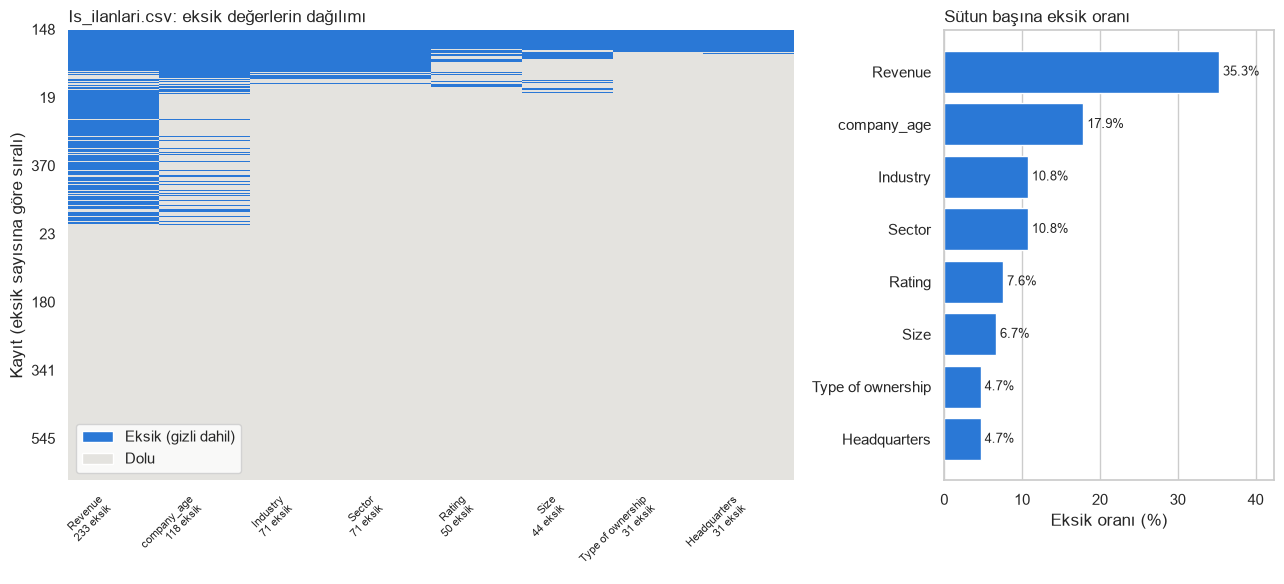

In [25]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# Eksik değerler (NaN + gizli eksik): her satır bir kayıt, her sütun bir değişken.
# Kayıtlar, eksik sütun sayısına göre sıralanır; böylece eksiklik kalıpları (hangi sütunlar birlikte eksik) görünür.
DOLU_RENK, EKSIK_RENK = "#e4e3df", "#2a78d6"
sutunlar = ham_eksik_ozeti.index.tolist()
sirali = eksik[sutunlar].loc[eksik.sum(axis=1).sort_values(ascending=False, kind="stable").index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [2.2, 1]})
sns.heatmap(sirali.astype(int), cmap=ListedColormap([DOLU_RENK, EKSIK_RENK]), vmin=0, vmax=1,
            cbar=False, yticklabels=100, ax=ax1)
ax1.set_xticklabels([f"{s}\n{ham_eksik_ozeti.loc[s, 'Eksik hücre']} eksik" for s in sutunlar], rotation=45, ha="right", fontsize=8)
ax1.set_xlabel("")
ax1.set_ylabel("Kayıt (eksik sayısına göre sıralı)")
ax1.tick_params(axis="y", rotation=0)
ax1.set_title("Is_ilanlari.csv: eksik değerlerin dağılımı", loc="left")
ax1.legend(handles=[Patch(facecolor=EKSIK_RENK, label="Eksik (gizli dahil)"), Patch(facecolor=DOLU_RENK, label="Dolu")],
           loc="lower left", frameon=True)

ax2.barh(ham_eksik_ozeti.index[::-1], ham_eksik_ozeti["Eksik (%)"][::-1], color=EKSIK_RENK)
for y, v in enumerate(ham_eksik_ozeti["Eksik (%)"][::-1]):
    ax2.text(v + 0.5, y, f"{v:.1f}%", va="center", fontsize=9)
ax2.set_xlim(0, ham_eksik_ozeti["Eksik (%)"].max() * 1.2)
ax2.set_xlabel("Eksik oranı (%)")
ax2.set_title("Sütun başına eksik oranı", loc="left")
ax2.grid(axis="y", visible=False)
fig.tight_layout()

fig.savefig(FIGURES / "is_ilanlari_eksik_isi_haritasi.png", dpi=150, bbox_inches="tight")
plt.show()

> **Eksiklik kalıbı:** Gizli eksik oranı en yüksek sütunlar `Revenue` (%35,3: 206 `Unknown / Non-Applicable` + 27 `-1`) ve `company_age` (%17,9); `Industry` ile `Sector` ise ikisi de 71 kayıtta ve her zaman birlikte eksik. 660 kaydın 375'inde hiç eksik yok, 192'sinde tek sütun eksik. Dikkat çekici nokta, 27 kayıtta 8 sütunun birden (`Headquarters`, `Size`, `Type of ownership`, `Industry`, `Sector`, `Revenue`, `Rating`, `company_age`) eksik olması: bunlar şirket bilgisi hiç toplanamamış ilanlar (tekrarlar silinince 16 kayıt kalıyor, bkz. 3.3). Isı haritasında bu kayıtlar üstte tek bir mavi blok olarak görünüyor. Yani eksikler rastgele dağılmıyor, birlikte kümeleniyor; bu da sonraki bölümde yöntem seçimini etkiliyor.

## 3. Eksik Veri Stratejisi ve Uygulama

Temizlenmiş tablo (`df`) artık bütün eksikleri `NaN` olarak taşıyor. Stratejiyi sütun türüne göre ayırıyoruz: iki sayısal sütun (`Rating`, `company_age`) yöntem karşılaştırmasıyla, metin sütunları ise anlamlarına göre doldurulur.

In [26]:
# Eksik hücre içeren sütunlar: sayısal ve metin olarak ayrı
eksik_ozeti = df.isna().sum()[lambda s: s > 0]
SAYISAL_SUTUNLAR = [s for s in eksik_ozeti.index if s not in metin_sutunlari]
KATEGORIK_SUTUNLAR = [s for s in eksik_ozeti.index if s in metin_sutunlari]
print("Sayısal   :", SAYISAL_SUTUNLAR)
print("Kategorik :", KATEGORIK_SUTUNLAR)
eksik_ozeti.to_frame("Eksik hücre").assign(**{"Eksik (%)": (100 * eksik_ozeti / len(df)).round(1)})

Sayısal   : ['Rating', 'company_age']
Kategorik : ['Headquarters', 'Size', 'Type of ownership', 'Industry', 'Sector', 'Revenue']


,Eksik hücre,Eksik (%)
Rating,39,6.0
Headquarters,20,3.1
Size,33,5.1
Type of ownership,20,3.1
Industry,60,9.3
Sector,60,9.3
Revenue,222,34.3
company_age,107,16.5


### 3.1 Ön kontrol: diğer sütunlar `Rating` ve `company_age`'i açıklıyor mu?

In [27]:
import warnings
import statsmodels.formula.api as smf

# Diğer sütunlar Rating ve company_age'i açıklıyor mu? (KNN'in işe yaraması için ön koşul)
# Her model yalnızca kullandığı sütunların hepsi dolu olan satırlarla kurulur.
modeller = {
    "Rating ~ Sector + Size + avg_salary": "Rating ~ C(Sector) + C(Size) + avg_salary",
    "company_age ~ Sector + Size + avg_salary": "company_age ~ C(Sector) + C(Size) + avg_salary",
    "company_age ~ Size": "company_age ~ C(Size)",
}
# Bazı Sector / Size kategorileri birbirini tamamen belirlediği için statsmodels "rank-deficient" uyarısı verir;
# bu, R² değerini değiştirmez (tahminler yine tek biçimde hesaplanır), bu yüzden uyarı bastırılır.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    r2_tablosu = pd.DataFrame([
        {"Model": ad, "Satır sayısı": int(sonuc.nobs), "R²": sonuc.rsquared, "Düzeltilmiş R²": sonuc.rsquared_adj}
        for ad, sonuc in ((ad, smf.ols(formul, data=df).fit()) for ad, formul in modeller.items())
    ]).set_index("Model")
r2_tablosu.round(3)

,Satır sayısı,R²,Düzeltilmiş R²
Model,,,
Rating ~ Sector + Size + avg_salary,576,0.227,0.188
company_age ~ Sector + Size + avg_salary,534,0.550,0.527
company_age ~ Size,537,0.423,0.417


> **Sonuç:** `Rating` için düzeltilmiş R² ≈ 0,19: sektör, şirket büyüklüğü ve maaş, puandaki değişimin yalnızca beşte birini açıklıyor (zayıf ilişki). `company_age` için ise düzeltilmiş R² ≈ 0,53, yalnızca `Size` ile bile ≈ 0,42: şirket büyüklüğü ve sektör şirketin yaşını makul ölçüde açıklıyor. Bu yüzden `company_age` için benzer kayıtlara bakan KNN işe yarayacak bir bilgiye sahip, `Rating` için ise KNN'in ortalamadan iyi tahmin etmesi beklenmez. Bu beklentiyi 3.2'de, gerçek değerleri gizleyerek sınıyoruz.

### 3.2 Yöntem karşılaştırması: ortalama, medyan, rastgele örnekleme, KNN

In [28]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

# KNN'in benzerliği ölçtüğü sütunlar: sayısal sütunlar, beceri işaretleri ve (sıralı sayıya çevrilmiş) şirket büyüklüğü
KNN_OZELLIKLERI = ["Rating", "company_age", "avg_salary", "python", "excel", "hadoop", "spark", "aws", "tableau", "big_data"]
BOYUT_SIRASI = {"1 to 50 employees": 1, "51 to 200 employees": 2, "201 to 500 employees": 3, "501 to 1000 employees": 4,
                "1001 to 5000 employees": 5, "5001 to 10000 employees": 6, "10000+ employees": 7}


# Doldurma fonksiyonları: aldıkları tabloyu değiştirmez, doldurulmuş yeni bir tablo döndürür
def ortalama_ile_doldur(veri):
    """Eksik hücreleri sütunun ortalamasıyla doldurur."""
    veri = veri.copy()
    for sutun in SAYISAL_SUTUNLAR:
        veri[sutun] = veri[sutun].fillna(veri[sutun].mean())
    return veri


def medyan_ile_doldur(veri):
    """Eksik hücreleri sütunun medyanıyla doldurur."""
    veri = veri.copy()
    for sutun in SAYISAL_SUTUNLAR:
        veri[sutun] = veri[sutun].fillna(veri[sutun].median())
    return veri


def rastgele_ornekle_doldur(veri, seed=42):
    """Eksik hücreleri, aynı sütunun dolu değerlerinden rastgele (yerine koyarak) seçilen değerlerle doldurur.
    Sabit seed: her çalıştırmada aynı sonuç."""
    veri = veri.copy()
    rng = np.random.default_rng(seed)
    for sutun in SAYISAL_SUTUNLAR:
        eksik = veri[sutun].isna()
        veri.loc[eksik, sutun] = rng.choice(veri[sutun].dropna().to_numpy(), size=eksik.sum())
    return veri


def knn_ile_doldur(veri, k=5):
    """Eksik hücreleri, benzer özelliklere sahip k kaydın ortalamasıyla doldurur.
    Sütunlar önce aynı ölçeğe getirilir; yoksa avg_salary (yüzlerce) mesafeyi tek başına belirlerdi."""
    veri = veri.copy()
    ozellik = veri[KNN_OZELLIKLERI].copy()
    ozellik["boyut_sirasi"] = veri["Size"].map(BOYUT_SIRASI)
    olcekleyici = StandardScaler()
    olcekli = olcekleyici.fit_transform(ozellik)                  # NaN'lar korunur
    dolu = KNNImputer(n_neighbors=k).fit_transform(olcekli)
    dolu = pd.DataFrame(olcekleyici.inverse_transform(dolu), columns=ozellik.columns, index=veri.index)
    for sutun in SAYISAL_SUTUNLAR:
        veri[sutun] = veri[sutun].fillna(dolu[sutun])
    return veri


yontemler = {
    "Ortalama": ortalama_ile_doldur,
    "Medyan": medyan_ile_doldur,
    "Rastgele örnekleme": rastgele_ornekle_doldur,
    "KNN (k=5)": knn_ile_doldur,
}
doldurulmus = {ad: yontem(df) for ad, yontem in yontemler.items()}

In [29]:
# Her yöntemden sonra ortalama ve standart sapma; orijinal = yalnızca dolu (gözlenen) değerler
yontem_ozetleri = {"Orijinal (dolu değerler)": df[SAYISAL_SUTUNLAR]} | {ad: v[SAYISAL_SUTUNLAR] for ad, v in doldurulmus.items()}
karsilastirma = pd.concat({ad: v.agg(["mean", "std"]).T.stack() for ad, v in yontem_ozetleri.items()}, axis=1).T
karsilastirma.columns = [f"{sutun} {'ortalama' if olcu == 'mean' else 'std'}" for sutun, olcu in karsilastirma.columns]
for sutun in SAYISAL_SUTUNLAR:
    orijinal_std = df[sutun].std()
    karsilastirma[f"{sutun} std değişimi (%)"] = 100 * (karsilastirma[f"{sutun} std"] / orijinal_std - 1)
karsilastirma.round(2)

,Rating ortalama,Rating std,company_age ortalama,company_age std,Rating std değişimi (%),company_age std değişimi (%)
Orijinal (dolu değerler),3.88,0.61,36.48,40.95,0.00,0.00
Ortalama,3.88,0.59,36.48,37.41,-3.06,-8.64
Medyan,3.88,0.59,33.92,37.85,-3.01,-7.57
Rastgele örnekleme,3.88,0.60,35.61,39.69,-1.05,-3.08
KNN (k=5),3.88,0.60,34.90,38.20,-2.02,-6.72


In [30]:
# company_age eksiği rastgele mi dağılmış? Küçük firmaların (en çok 200 çalışan) payı: tüm kayıtlarda ve eksik olanlarda
KUCUK_FIRMA = df["Size"].isin(["1 to 50 employees", "51 to 200 employees"])
bilinen_boyut = df["Size"].notna()
pd.Series({
    "Küçük firma oranı, tüm kayıtlar": KUCUK_FIRMA[bilinen_boyut].mean(),
    "Küçük firma oranı, company_age eksik olanlar": KUCUK_FIRMA[bilinen_boyut & df["company_age"].isna()].mean(),
}).round(2)

Küçük firma oranı, tüm kayıtlar                 0.34
Küçük firma oranı, company_age eksik olanlar    0.72
dtype: float64

> **Eksiklik rastgele değil (`company_age`):** Yaşı eksik olan kayıtların büyük çoğunluğu küçük firmalar. Bu, aşağıdaki maskeli doğrulamayı etkiliyor: bilinen değerleri **rastgele** gizlersek eksikliğin de rastgele olduğunu varsaymış oluruz ve hata ölçüleri ağırlıklı olarak büyük / orta firmaları (tipik satırları) ölçer, gerçekte doldurulan satırları değil. Bu yüzden doğrulama iki şekilde yapılır: (1) tüm bilinen değerlerden rastgele gizleyerek, (2) yalnızca küçük firmaların değerlerini gizleyerek (gerçek eksiklik kalıbına daha yakın).

In [31]:
# Dağılım şeklini bozmadan doldurmak yetmez, doldurulan değerler gerçeğe de yakın olmalı.
# Maskeli doğrulama: bilinen değerlerin %20'sini gizle, yöntemle doldur, gerçek değerlerle karşılaştır (RMSE: küçük = iyi).
def maskeli_dogrulama(yontem, sutun, havuz=None, oran=0.2, tekrar=30, seed=0):
    """Bilinen değerlerin rastgele %20'sini gizler, yöntemle doldurur ve gerçek değerlerle RMSE hesaplar.
    havuz: gizlenecek değerlerin seçileceği satırlar (True/False Series); None ise bilinen tüm değerler.
    Farklı gizleme kümeleriyle 'tekrar' kez yapılır, ortalaması alınır."""
    rng = np.random.default_rng(seed)
    uygun = df[sutun].notna() if havuz is None else (df[sutun].notna() & havuz)
    bilinen = df.index[uygun]
    hatalar = []
    for _ in range(tekrar):
        gizlenen = rng.choice(bilinen, size=int(oran * len(bilinen)), replace=False)
        kopya = df.copy()
        kopya.loc[gizlenen, sutun] = np.nan
        doldurulmus_kopya = yontem(kopya)
        hatalar.append(np.sqrt(((doldurulmus_kopya.loc[gizlenen, sutun] - df.loc[gizlenen, sutun]) ** 2).mean()))
    return np.mean(hatalar)


havuzlar = {"Tüm kayıtlardan gizlenen": None, "Küçük firmalardan gizlenen": KUCUK_FIRMA}
rmse_tablosu = pd.DataFrame({
    (havuz_adi, sutun): {ad: maskeli_dogrulama(yontem, sutun, havuz) for ad, yontem in yontemler.items()}
    for havuz_adi, havuz in havuzlar.items() for sutun in SAYISAL_SUTUNLAR
})
rmse_tablosu.round(3)

Tüm kayıtlardan gizlenen              \
                                     Rating company_age   
Ortalama                              0.610      40.128   
Medyan                                0.614      42.508   
Rastgele örnekleme                    0.862      58.211   
KNN (k=5)                             0.620      34.550   

                   Küçük firmalardan gizlenen              
                                       Rating company_age  
Ortalama                                0.732      25.628  
Medyan                                  0.757      12.279  
Rastgele örnekleme                      0.941      44.312  
KNN (k=5)                               0.734      12.154

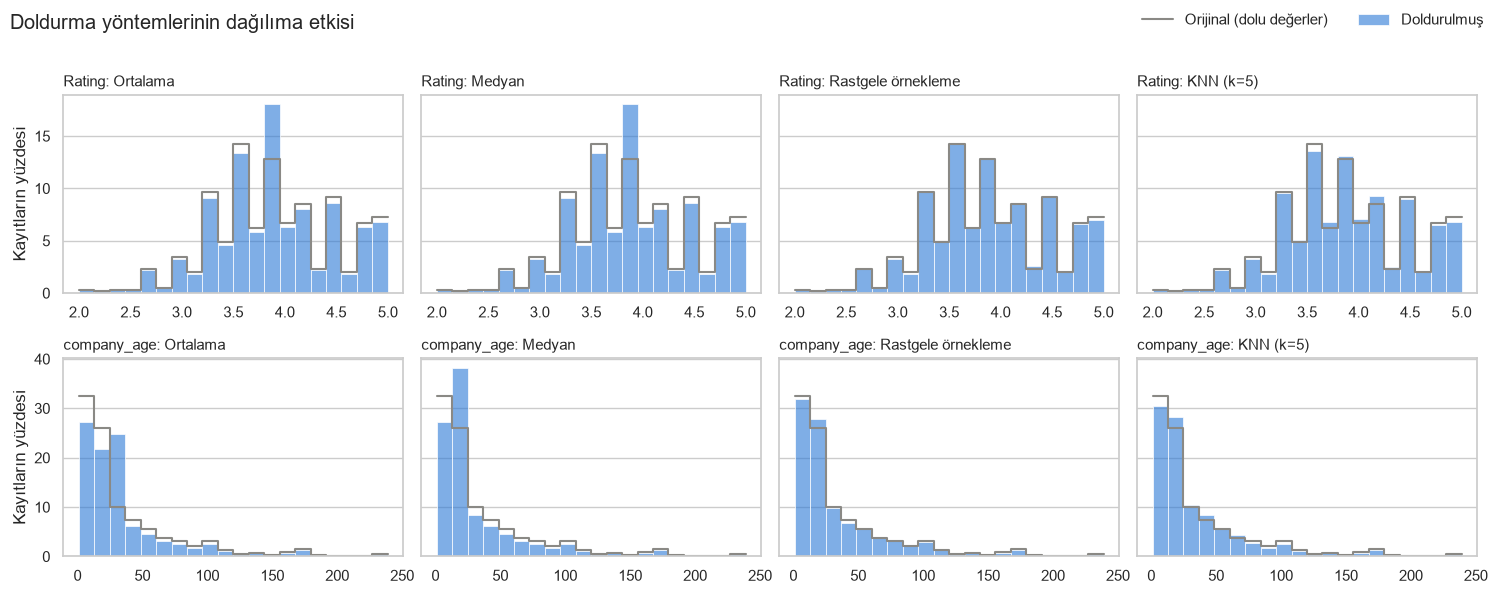

In [32]:
# Her panel: orijinal dolu değerlerin dağılımı (gri çizgi) ve yöntem uygulandıktan sonraki dağılım (mavi)
ORIJINAL_RENK, DOLDURULMUS_RENK = "#8a8985", "#2a78d6"
fig, axes = plt.subplots(len(SAYISAL_SUTUNLAR), len(yontemler), figsize=(15, 6), sharey="row")
for satir, sutun in enumerate(SAYISAL_SUTUNLAR):
    kutular = np.histogram_bin_edges(df[sutun].dropna(), bins=20)   # aynı satırdaki paneller aynı kutuları kullanır
    for kolon, (ad, veri) in enumerate(doldurulmus.items()):
        ax = axes[satir, kolon]
        sns.histplot(veri[sutun], bins=kutular, stat="percent", color=DOLDURULMUS_RENK, alpha=0.6,
                     edgecolor="white", linewidth=0.5, ax=ax, label="Doldurulmuş")
        sns.histplot(df[sutun].dropna(), bins=kutular, stat="percent", element="step", fill=False,
                     color=ORIJINAL_RENK, linewidth=1.5, ax=ax, label="Orijinal (dolu değerler)")
        ax.set_title(f"{sutun}: {ad}", loc="left", fontsize=11)
        ax.set_xlabel("")
        ax.set_ylabel("Kayıtların yüzdesi" if kolon == 0 else "")
        ax.grid(axis="x", visible=False)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper right", ncol=2, frameon=False)
fig.suptitle("Doldurma yöntemlerinin dağılıma etkisi", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.97))

fig.savefig(FIGURES / "is_ilanlari_doldurma_karsilastirmasi.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.3 Seçim ve uygulama

> **Seçilen yöntemler: `Rating` için ortalama, `company_age` için KNN.**
>
> **`Rating`:** Dağılım simetrik (çarpıklık ≈ 0,01) ve yalnızca %6 eksik. Her iki doğrulamada da (tüm kayıtlardan veya küçük firmalardan gizlenen) ortalama, medyan ve KNN pratikte aynı hatayı veriyor (tüm kayıtlar: 0,610 / 0,614 / 0,620; küçük firmalar: 0,732 / 0,757 / 0,734). Diğer sütunlar zayıf ilişkileri (R² ≈ 0,19) yüzünden KNN'e üstünlük sağlamıyor, eşit doğrulukta en basit yöntem seçildi. Bedeli: 39 hücreye aynı değer (3,88) yazıldığı için bu hücrelerde varyans sıfır; ancak eksik oranı düşük olduğundan sütunun standart sapması yalnızca %3 azalıyor. Rastgele örnekleme dağılımı daha iyi korur ama hata çok daha yüksek (0,862).
>
> **`company_age`:** Sağa çok çarpık (çarpıklık ≈ 2,2; ortalama 36, medyan 21) ve %16,5 eksik. Eksikler rastgele değil: büyüklüğü bilinen firmalar arasında küçük firma oranı tüm kayıtlarda 0,34 iken yaşı eksik olanlarda 0,72. Bu yüzden asıl bakılacak sonuç, gerçek eksiklik kalıbına yakın olan 'küçük firmalardan gizlenen' doğrulama: orada ortalama (RMSE 25,6) açık farkla kötü, çünkü tüm firmaların tipik yaşını küçük firmalara yazıyor. Medyan (12,3) ve KNN (12,2) neredeyse eşit; rastgele örnekleme en kötüsü (44,3). Tüm kayıtlardan rastgele gizlemede ise KNN açık farkla en iyi (34,55; ortalama 40,1; medyan 42,5). KNN iki durumda da en iyi ya da en iyiye eşit olduğu ve tek bir değere yığılma yaratmadığı için seçildi: medyan 107 hücreye aynı değeri yazar, KNN benzer firmaların yaşını kullanır. Sınırlılık: komşuların ortalaması alındığı için doldurulan değerler dar bir aralıkta kalıyor (doldurulanların std'si ≈ 17, gözlenenlerinki ≈ 41); bu, 5. bölümde ayrıca gösterilir. Yıl tam sayı olduğu için KNN sonucu en yakın tam sayıya yuvarlanır.

In [33]:
def sayisal_doldur(veri):
    """Seçilen yöntemler: Rating -> ortalama, company_age -> KNN (k=5, sonuç tam yıla yuvarlanır)."""
    veri = veri.copy()
    veri["Rating"] = ortalama_ile_doldur(veri)["Rating"]
    veri["company_age"] = knn_ile_doldur(veri)["company_age"].round()
    return veri


df_sayisal = sayisal_doldur(df)

# Kontrol: sayısal eksik kalmamalı
df_sayisal[SAYISAL_SUTUNLAR].isna().sum()

Rating         0
company_age    0
dtype: int64

In [34]:
# Metin içindeki sayıları doğrulayan kontrol: şirket bilgisi tamamen eksik ilan ve Revenue eksiği
sirket_sutunlari = ["Headquarters", "Size", "Type of ownership", "Industry", "Sector", "Revenue", "Rating", "company_age"]
tam_eksik = df[sirket_sutunlari].isna().all(axis=1)
print(f"Şirket bilgisi tamamen eksik ilan: {tam_eksik.sum()} (ham veride {eksik_maskesi(ham)[sirket_sutunlari].all(axis=1).sum()}, gerisi tekrar olarak silindi)")
revenue_eksik = df["Revenue"].isna()
print(f"Revenue eksik: {revenue_eksik.sum()} ilan, {df.loc[revenue_eksik, 'Company Name'].nunique()} farklı şirket")

Şirket bilgisi tamamen eksik ilan: 16 (ham veride 27, gerisi tekrar olarak silindi)
Revenue eksik: 222 ilan, 155 farklı şirket


**Kategorik sütunlar: `Bilinmiyor` etiketi.** Metin sütunlarındaki eksikler mod (en sık değer) ile doldurulmaz: `Revenue`'de eksik oranı %34 (222 ilan, 155 farklı şirket); bunlara tek bir gelir aralığı yazmak, hepsine uydurma bir bilgi vermek olurdu. Ayrıca bu bilginin eksik olması da bir şey söylüyor (ör. gelir bilgisi paylaşılmayan şirketler); `Bilinmiyor` ayrı bir kategori olarak bunu korur. Şirket bilgisi tamamen eksik olan ilanlar (yukarıdaki çıktıdaki sayı) silinmedi, çünkü maaş, beceri ve açıklama bilgisi taşıyorlar. `job_simp` ve `seniority` kategori etiketi oldukları için bu adımın dışında. `Location = United States` / `job_state = US` değerleri de eksik sayılmadı (bkz. 1.1). Sıra önemli: KNN `Size` sütununu kullandığı için sayısal doldurma önce yapılır.

In [35]:
def kategorik_bilinmiyor_yap(veri):
    """Metin sütunlarındaki eksikleri 'Bilinmiyor' etiketiyle doldurur."""
    veri = veri.copy()
    for sutun in KATEGORIK_SUTUNLAR:
        veri[sutun] = veri[sutun].fillna("Bilinmiyor")
    return veri


# Önce sayısal doldurma (KNN, Size sütununu kullanır), sonra Size'daki eksikler etiketlenir; sıra önemlidir
df_doldurulmus = kategorik_bilinmiyor_yap(df_sayisal)

# Kontrol: hiçbir sütunda eksik kalmamalı
print("Kalan eksik hücre:", int(df_doldurulmus.isna().sum().sum()))
df_doldurulmus[KATEGORIK_SUTUNLAR].apply(lambda s: (s == "Bilinmiyor").sum()).to_frame("'Bilinmiyor' sayısı")

Kalan eksik hücre: 0


,'Bilinmiyor' sayısı
Headquarters,20
Size,33
Type of ownership,20
Industry,60
Sector,60
Revenue,222


## 4. Aykırı Değer (Outlier) Analizi

Aykırı değer analizi, eksikleri doldurulmuş tablo (`df_doldurulmus`) üzerinde, ölçeği anlamlı sayısal sütunlarda yapılır: `min_salary`, `max_salary`, `avg_salary` (bin dolar), `Rating` ve `company_age`. İşaret sütunları (0/1) ve eyalet gibi kategorik sütunlar kapsam dışıdır. Tespit için iki bağımsız yöntem (IQR ve Z-skoru) kullanılır, sonuç box plot ile gösterilir.

In [36]:
from scipy import stats

ANALIZ_SUTUNLARI = ["min_salary", "max_salary", "avg_salary", "Rating", "company_age"]


def iqr_sinirlari(seri, katsayi=1.5, log=False):
    """IQR yöntemi: [Q1 - 1.5*IQR, Q3 + 1.5*IQR] aralığının dışındaki değerler aykırı sayılır.
    log=True: sınırlar log(1+x) ölçeğinde hesaplanıp geri çevrilir (sağa çarpık sütunlar için)."""
    x = np.log1p(seri) if log else seri
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    alt, ust = q1 - katsayi * iqr, q3 + katsayi * iqr
    return (np.expm1(alt), np.expm1(ust)) if log else (alt, ust)


def aykiri_raporu(veri, sutunlar, log_sutunlar=()):
    """Her sütun için IQR sınırları, IQR ve Z-skoru (|z| > 3) ile bulunan aykırı sayıları. Veriyi değiştirmez.
    log_sutunlar'daki sütunlar için ayrıca bir "(log ölçeği)" satırı eklenir: o satırda IQR, Z-skoru ve çarpıklık log(1+x)
    ölçeğinde hesaplanır (en küçük / en büyük değer ve sınırlar yine orijinal birimde gösterilir)."""
    satirlar = []
    for sutun in sutunlar:
        seri = veri[sutun].dropna().astype(float)
        for log in ([False, True] if sutun in log_sutunlar else [False]):
            x = np.log1p(seri) if log else seri
            z = np.abs(stats.zscore(x))
            alt, ust = iqr_sinirlari(seri, log=log)
            satirlar.append({
                "Sütun": sutun + (" (log ölçeği)" if log else ""),
                "En küçük": seri.min(), "En büyük": seri.max(),
                "Alt sınır": alt, "Üst sınır": ust,
                "IQR aykırı": int(((seri < alt) | (seri > ust)).sum()),
                "Z-skoru aykırı (|z|>3)": int((z > 3).sum()),
                "Çarpıklık": x.skew(),
            })
    return pd.DataFrame(satirlar).set_index("Sütun")


aykiri_raporu(df_doldurulmus, ANALIZ_SUTUNLARI, log_sutunlar=["company_age"]).round(2)

,En küçük,En büyük,Alt sınır,Üst sınır,IQR aykırı,Z-skoru aykırı (|z|>3),Çarpıklık
Sütun,,,,,,,
min_salary,31.0,212.0,14.50,186.50,21,21,1.09
max_salary,56.0,331.0,50.00,234.00,21,21,1.68
avg_salary,43.0,271.0,53.50,185.50,41,21,1.51
Rating,2.0,5.0,2.30,5.50,4,2,0.01
company_age,1.0,239.0,-38.50,93.50,56,19,2.33
company_age (log ölçeği),1.0,239.0,0.65,325.78,0,0,0.09


In [37]:
# Hangi değerler aykırı? Aynı üçlü mü tekrar ediyor, bu ilanlar veride başka bir kopyasıyla da var mı?
alt, ust = iqr_sinirlari(df_doldurulmus["max_salary"])
uc = df_doldurulmus["max_salary"] > ust
baska_kopya = (df_doldurulmus.loc[uc, ILAN_ANAHTARI]
               .merge(df_doldurulmus.loc[~uc, ILAN_ANAHTARI].drop_duplicates(), on=ILAN_ANAHTARI, how="left", indicator=True)
               ["_merge"].eq("both").sum())
print(f"Uç maaşlı {uc.sum()} ilandan {baska_kopya} tanesi, normal maaşlı başka bir kopyasıyla da veride geçiyor (bkz. 1.1, 'Aynı ilan, farklı maaş')")
df_doldurulmus.loc[uc, ["min_salary", "max_salary", "avg_salary"]].value_counts().to_frame("İlan sayısı")

Uç maaşlı 21 ilandan 12 tanesi, normal maaşlı başka bir kopyasıyla da veride geçiyor (bkz. 1.1, 'Aynı ilan, farklı maaş')


,,,İlan sayısı
min_salary,max_salary,avg_salary,
212,331,271,21


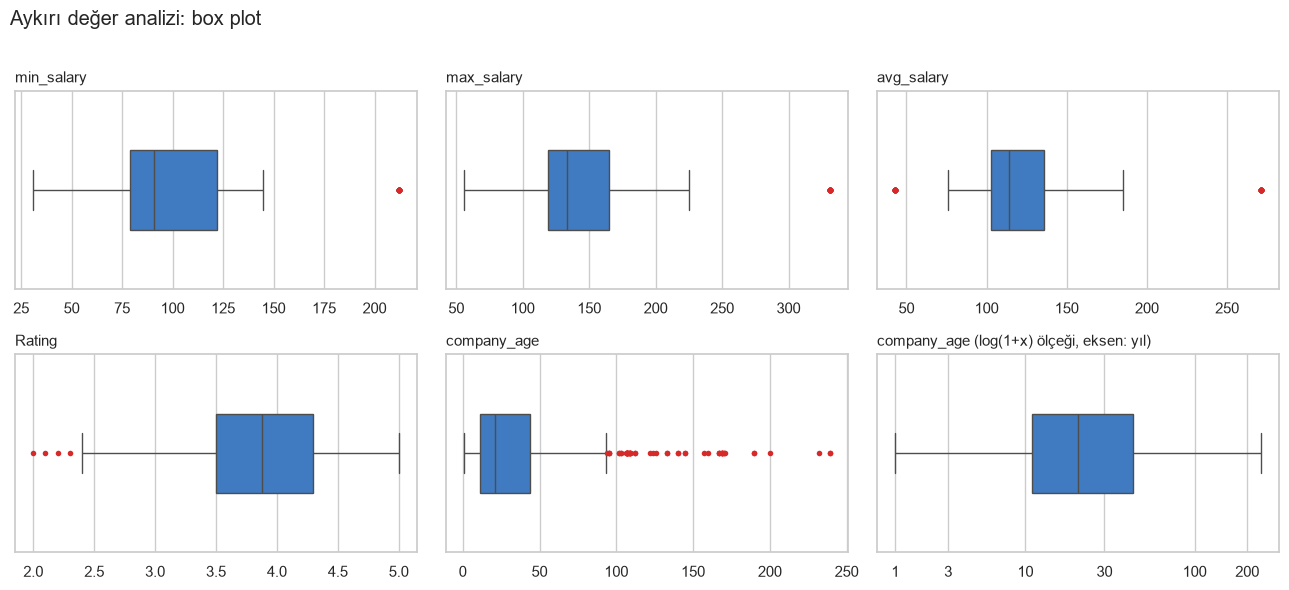

In [38]:
# Box plot (önce): sınırların dışındaki noktalar kırmızıyla ayrıca çizilir
KUTU_RENK = "#2a78d6"
AYKIRI_STIL = {"marker": "o", "markerfacecolor": "#d62a2a", "markersize": 4, "markeredgecolor": "none"}

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, sutun in zip(axes.flat, ANALIZ_SUTUNLARI):
    sns.boxplot(x=df_doldurulmus[sutun], color=KUTU_RENK, width=0.4, ax=ax, flierprops=AYKIRI_STIL)
    ax.set_title(f"{sutun}", loc="left", fontsize=11)
    ax.set_xlabel("")
# company_age çok sağa çarptığı için bir de log(1+x) ölçeğinde gösterilir. Veri çizimden önce dönüştürülür: böylece kutu ve
# bıyıklar aykırı değer tablosundaki "(log ölçeği)" satırıyla aynı ölçekte hesaplanır. (Ekseni çizimden sonra logaritmik
# yapmak yetmez: sınırlar ham ölçekte hesaplanmış kalır ve log ölçeğinde aykırı olmayan değerler aykırı gibi görünür.)
# Eksen etiketleri yine yıl olarak yazılır.
ax_log = axes.flat[5]
sns.boxplot(x=np.log1p(df_doldurulmus["company_age"]), color=KUTU_RENK, width=0.4, ax=ax_log, flierprops=AYKIRI_STIL)
yillar = [1, 3, 10, 30, 100, 200]
ax_log.set_xticks(np.log1p(yillar), labels=[str(y) for y in yillar])
ax_log.set_title("company_age (log(1+x) ölçeği, eksen: yıl)", loc="left", fontsize=11)
ax_log.set_xlabel("")
fig.suptitle("Aykırı değer analizi: box plot", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.97))

fig.savefig(FIGURES / "is_ilanlari_aykiri_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

> **Tespit:**
> - **Maaş sütunları:** IQR ve Z-skoru aynı 21 ilanı işaret ediyor (min 212, max 331, avg 271); box plot'ta kutunun çok sağında kırmızı noktalar olarak görünüyor. Bu 21 ilan tek bir `Salary Estimate` bloğuna ait, ancak 1.1'de gösterildiği gibi maaş zaten ilan bazında güvenilir değil ve 21 ilanın 12'si veride normal maaşla da geçiyor. `avg_salary` için IQR 41 aykırı buluyor: 21 üst uç ve 20 alt uç; alt uçtakilerin (avg 43, min 31, max 56) `min_salary` ve `max_salary` sınırları içinde olduğu, yani düşük ama tutarlı tahminler olduğu görülüyor.
> - **`Rating`:** IQR 4 puanı aykırı işaretliyor: alt sınırın (2,3) altındaki 2,0, 2,1 ve 2,2 ile sınıra eşit olan 2,3. Sonuncusu bir kayan nokta yuvarlaması: sınır 2,3 yerine 2,3000…03 hesaplandığı için 2,3 de sınırın altında kalıyor. Puan 1–5 ölçeğinde olduğu için 2,0–2,3 gibi değerler olası ve gerçek. Değiştirilmez.
> - **`company_age`:** Ham IQR 56 aykırı buluyor, ama sütun çok sağa çarpık (çarpıklık ≈ 2,3): yaşı 100'ün üstündeki firmalar bu veride gerçek değerler. Dağılım çarpık olduğunda IQR ve Z-skoru uzun kuyruğu yanlışlıkla aykırı sayar. Log ölçeğinde (çarpıklık 0,09) hem IQR hem Z-skoru 0 aykırı buluyor (tablonun son satırı, box plot'un sağ alt paneli). Değiştirilmez.
>
> **Karar:** Yalnızca maaşın üst ucundaki 21 ilan baskılanır (satır silinmez; ilanın geri kalan bilgileri geçerli). Bu karar muhafazakâr: baskılama yalnızca en uç değerleri sınıra çeker.

In [39]:
def maas_baskila(veri):
    """min_salary ve max_salary'yi kendi IQR sınırlarında baskılar (winsorize); satır silmez.
    avg_salary bunlardan türetilen bir sütun olduğu için orijinal veride kullanılan kuralla, yani (min+max)'ın yarısının
    tam kısmıyla yeniden hesaplanır; Salary Estimate metni de yeni min-max değerlerinden üretilir. Böylece üç maaş
    sütunu birbiriyle tutarlı kalır."""
    veri = veri.copy()
    for sutun in ["min_salary", "max_salary"]:
        alt, ust = iqr_sinirlari(veri[sutun])
        veri[sutun] = veri[sutun].clip(alt, ust).round().astype(int)
    veri["avg_salary"] = (veri["min_salary"] + veri["max_salary"]) // 2
    veri["Salary Estimate"] = veri["min_salary"].astype(str) + "-" + veri["max_salary"].astype(str)
    return veri


df_aykirisiz = maas_baskila(df_doldurulmus)

# Kontrol: kaç maaş hücresi değişti?
maas_sutunlari = ["min_salary", "max_salary", "avg_salary"]
(df_aykirisiz[maas_sutunlari] != df_doldurulmus[maas_sutunlari]).sum().to_frame("Değişen hücre")

,Değişen hücre
min_salary,21
max_salary,21
avg_salary,21


In [40]:
# Önce / sonra aykırı sayıları. IQR sınırları baskılamadan ÖNCEKİ verinin sınırlarıdır (aynı ölçüt uygulanır);
# Z-skoru ise her tablonun kendi ortalama ve standart sapmasıyla hesaplanır.
def baskilama_etkisi(veri, referans, sutunlar):
    """'referans' tablosundan hesaplanan IQR sınırlarına göre 'veri'de kaç değer dışarıda kalıyor? Z-skoru için de aynı sayım."""
    satirlar = {}
    for sutun in sutunlar:
        alt, ust = iqr_sinirlari(referans[sutun])
        satirlar[sutun] = {
            "Alt sınır": alt, "Üst sınır": ust,
            "IQR aykırı (önce)": int(((referans[sutun] < alt) | (referans[sutun] > ust)).sum()),
            "IQR aykırı (sonra)": int(((veri[sutun] < alt) | (veri[sutun] > ust)).sum()),
            "|z|>3 aykırı (önce)": int((np.abs(stats.zscore(referans[sutun])) > 3).sum()),
            "|z|>3 aykırı (sonra)": int((np.abs(stats.zscore(veri[sutun])) > 3).sum()),
        }
    return pd.DataFrame(satirlar).T


baskilama_etkisi(df_aykirisiz, df_doldurulmus, maas_sutunlari).round(2)

,Alt sınır,Üst sınır,IQR aykırı (önce),IQR aykırı (sonra),|z|>3 aykırı (önce),|z|>3 aykırı (sonra)
min_salary,14.5,186.5,21.0,0.0,21.0,0.0
max_salary,50.0,234.0,21.0,0.0,21.0,0.0
avg_salary,53.5,185.5,41.0,41.0,21.0,0.0


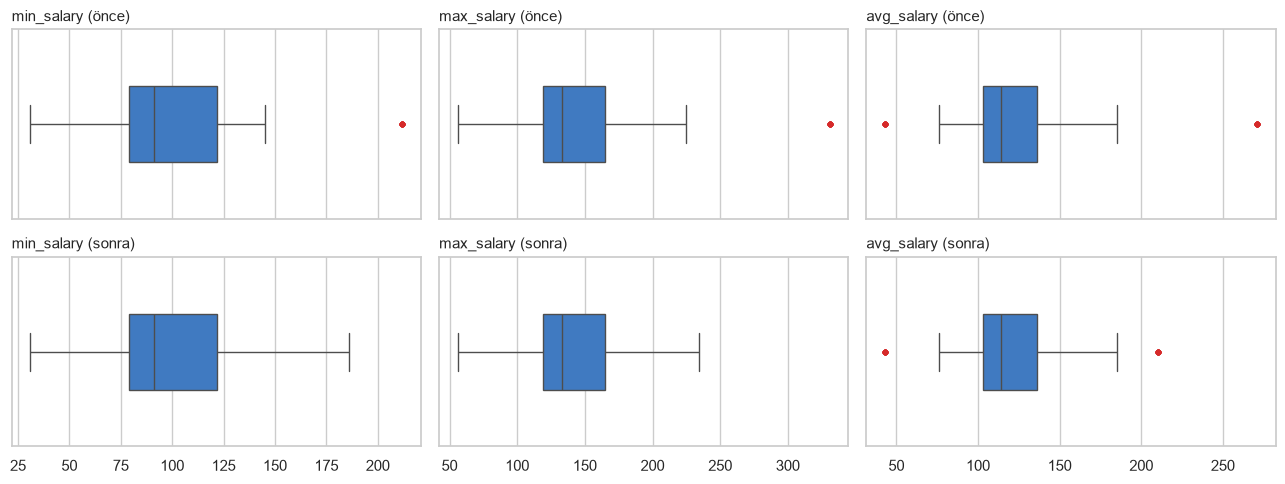

In [41]:
# Box plot (sonra): maaş sütunları baskılama sonrası, aynı eksenlerde
fig, axes = plt.subplots(2, 3, figsize=(13, 5), sharex="col")
for ust_sira, (veri, etiket) in enumerate([(df_doldurulmus, "önce"), (df_aykirisiz, "sonra")]):
    for ax, sutun in zip(axes[ust_sira], maas_sutunlari):
        sns.boxplot(x=veri[sutun], color=KUTU_RENK, width=0.4, ax=ax, flierprops=AYKIRI_STIL)
        ax.set_title(f"{sutun} ({etiket})", loc="left", fontsize=11)
        ax.set_xlabel("")
fig.tight_layout()

fig.savefig(FIGURES / "is_ilanlari_maas_boxplot_once_sonra.png", dpi=150, bbox_inches="tight")
plt.show()

> **Sonuç:** `min_salary` ve `max_salary` artık kendi IQR sınırlarının içinde (aykırı 21 → 0) ve hiçbir maaş sütununda |z| > 3 değer kalmadı. Değişiklik yalnızca o 21 ilanda: aralık 212–331 yerine 186–234, `avg_salary` 271 yerine 210; diğer satırlara dokunulmadı. `avg_salary` orijinal kuralla (min+max'ın yarısının tam kısmı) yeniden hesaplandığı için üç maaş sütunu tutarlı kalıyor.
>
> **Kalan IQR uyarısı:** `avg_salary` için IQR hâlâ 41 aykırı gösteriyor: 21'i baskılanan ilanlar (210, avg'nin üst sınırı olan 185,5'in üstünde ama artık Z-skoru ≈ 2,6, uç değil), 20'si ise yukarıda açıklanan, düşük ama geçerli maaşlar. `avg_salary`'yi ayrıca kendi sınırına çekmek, `min`, `max` ve `avg` arasındaki ilişkiyi bozardı; bu bilinçli bir ödünleşim.

## 5. Temizlik Sonrası Dağılım Kontrolü

Doldurma ve baskılamanın dağılımı bozup bozmadığı, ortalama / standart sapma / medyan / çarpıklık karşılaştırması ve histogramlarla kontrol edilir; doldurulan hücreler ayrıca ayrı bir tabloda incelenir. (Önce / sonra karşılaştırması bir istatistik testiyle kanıtlanmaz: iki tablo aynı değerlerin büyük kısmını içerdiği için bağımsız iki örneklem değildir ve KS gibi testler neredeyse her zaman ‘fark yok’ der.) Karşılaştırma, **temizlik öncesi gözlenen dolu değerler** (`df`, eksikler boş; ham tablodaki gizli eksikler hesaba katılmaz) ile **temizlik sonrası tablo** (`df_aykirisiz`) arasında yapılır.

In [42]:
KONTROL_SUTUNLARI = ["Rating", "company_age", "min_salary", "max_salary", "avg_salary"]


def dagilim_ozeti(veri, sutunlar):
    """Dolu hücre sayısı, ortalama, standart sapma, medyan, çarpıklık, en küçük ve en büyük değerler."""
    ozet = veri[sutunlar].astype(float).agg(["count", "mean", "std", "median", "skew", "min", "max"]).T
    return ozet


once = dagilim_ozeti(df, KONTROL_SUTUNLARI)
sonra = dagilim_ozeti(df_aykirisiz, KONTROL_SUTUNLARI)

display(pd.concat({"Önce (dolu değerler)": once, "Sonra (temiz)": sonra}, axis=1).round(2))
pd.DataFrame({
    "Ortalama değişimi (%)": 100 * (sonra["mean"] / once["mean"] - 1),
    "Std değişimi (%)": 100 * (sonra["std"] / once["std"] - 1),
    "Medyan değişimi (%)": 100 * (sonra["median"] / once["median"] - 1),
}).round(2)

Önce (dolu değerler)                                           \
                           count    mean    std median  skew   min    max   
Rating                     609.0    3.88   0.61    3.8  0.01   2.0    5.0   
company_age                541.0   36.48  40.95   21.0  2.17   1.0  239.0   
min_salary                 648.0   99.15  33.40   91.0  1.09  31.0  212.0   
max_salary                 648.0  148.58  48.61  133.0  1.68  56.0  331.0   
avg_salary                 648.0  123.68  40.10  114.0  1.51  43.0  271.0   

            Sonra (temiz)                                            
                    count    mean    std  median  skew   min    max  
Rating              648.0    3.88   0.59    3.88  0.01   2.0    5.0  
company_age         648.0   34.98  38.22   21.00  2.33   1.0  239.0  
min_salary          648.0   98.31  30.76   91.00  0.60  31.0  186.0  
max_salary          648.0  145.44  38.86  133.00  0.52  56.0  234.0  
avg_salary          648.0  121.70  33.79  114.00  0.54  43.0  210.0

,Ortalama değişimi (%),Std değişimi (%),Medyan değişimi (%)
Rating,0.00,-3.06,2.1
company_age,-4.12,-6.66,0.0
min_salary,-0.85,-7.90,0.0
max_salary,-2.12,-20.06,0.0
avg_salary,-1.60,-15.74,0.0


In [43]:
# Doldurulan hücrelerin kendisi nasıl? Eksik olup sonradan doldurulan değerler ile gözlenen (dolu) değerlerin karşılaştırması.
# (Önce / sonra tablosunda dolu değerler iki tarafta da yer aldığı için doldurulan kısım orada seyrelir; burada ayrı bakılır.)
def doldurulan_ozeti(onceki, sonraki, sutunlar):
    """Doldurulan hücrelerin değerlerinin özeti ile gözlenen değerlerin özeti."""
    satirlar = {}
    for sutun in sutunlar:
        eksikti = onceki[sutun].isna()
        gozlenen = onceki.loc[~eksikti, sutun].astype(float)
        doldurulan = sonraki.loc[eksikti, sutun].astype(float)
        satirlar[sutun] = {
            "Doldurulan hücre sayısı": len(doldurulan),
            "Gözlenen: ortalama": gozlenen.mean(), "Doldurulan: ortalama": doldurulan.mean(),
            "Gözlenen: std": gozlenen.std(), "Doldurulan: std": doldurulan.std(),
            "Gözlenen: medyan": gozlenen.median(), "Doldurulan: medyan": doldurulan.median(),
        }
    return pd.DataFrame(satirlar).T


doldurulan_ozeti(df, df_aykirisiz, SAYISAL_SUTUNLAR).round(2)

,Doldurulan hücre sayısı,Gözlenen: ortalama,Doldurulan: ortalama,Gözlenen: std,Doldurulan: std,Gözlenen: medyan,Doldurulan: medyan
Rating,39.0,3.88,3.88,0.61,0.00,3.8,3.88
company_age,107.0,36.48,27.37,40.95,17.48,21.0,23.00


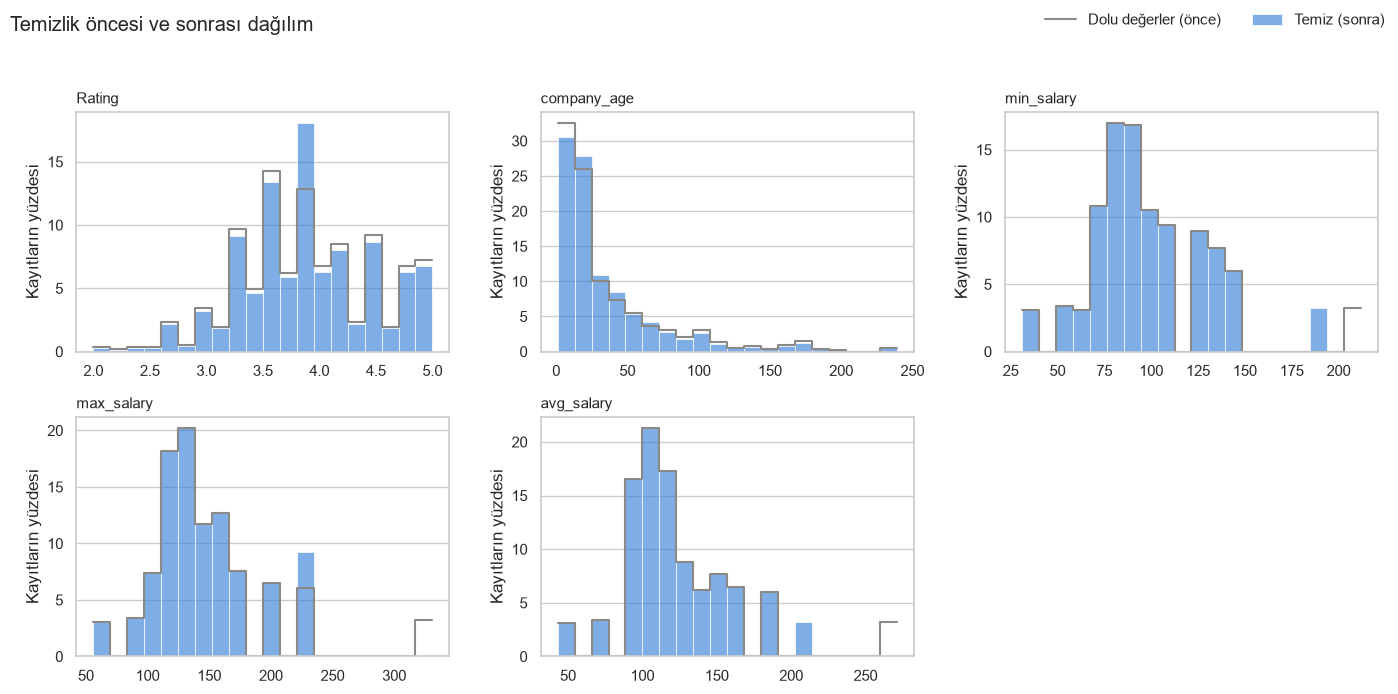

In [44]:
# Histogramlar: gri çizgi = önceki dolu değerler, mavi = temiz veri (aynı kutular, yüzde olarak)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, sutun in zip(axes.flat, KONTROL_SUTUNLARI):
    kutular = np.histogram_bin_edges(df[sutun].dropna().astype(float), bins=20)
    sns.histplot(df_aykirisiz[sutun].astype(float), bins=kutular, stat="percent", color=DOLDURULMUS_RENK,
                 alpha=0.6, edgecolor="white", linewidth=0.5, ax=ax, label="Temiz (sonra)")
    sns.histplot(df[sutun].dropna().astype(float), bins=kutular, stat="percent", element="step", fill=False,
                 color=ORIJINAL_RENK, linewidth=1.5, ax=ax, label="Dolu değerler (önce)")
    ax.set_title(sutun, loc="left", fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("Kayıtların yüzdesi")
    ax.grid(axis="x", visible=False)
axes.flat[5].axis("off")
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="upper right", ncol=2, frameon=False)
fig.suptitle("Temizlik öncesi ve sonrası dağılım", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.95))

fig.savefig(FIGURES / "is_ilanlari_temizlik_sonrasi_dagilim.png", dpi=150, bbox_inches="tight")
plt.show()

In [45]:
# Kategorik sütunlar: yer tutucular ve yazım farkları temizlenince farklı değer sayısı nasıl değişti?
kategorik_kontrol = ["Job Title", "Headquarters", "Size", "Type of ownership", "Industry", "Sector", "Revenue", "job_state"]
pd.DataFrame({
    "Önce (ham): farklı değer": ham[kategorik_kontrol].nunique(),
    "Sonra (temiz): farklı değer": df_aykirisiz[kategorik_kontrol].nunique(),
    "'Bilinmiyor' sayısı": (df_aykirisiz[kategorik_kontrol] == "Bilinmiyor").sum(),
})

,Önce (ham): farklı değer,Sonra (temiz): farklı değer,'Bilinmiyor' sayısı
Job Title,168,162,0
Headquarters,227,226,20
Size,9,8,33
Type of ownership,13,12,20
Industry,58,58,60
Sector,23,23,60
Revenue,14,13,222
job_state,39,39,0


> **Sonuç — temizlik dağılımı bozmadı (bilinçli değişiklikler hariç):**
> - **`Rating`:** Ortalama değişmedi (3,88), standart sapma %3 azaldı, çarpıklık aynı (0,01). Medyan %2 yükseldi (3,8 → 3,88): 39 hücre ortalamayla doldurulduğu için doğal. Doldurulan hücrelerin hepsi 3,88 (std 0), yani küçük bir yığılma var; eksik oranı %6 olduğu için genel dağılımı belirgin değiştirmiyor.
> - **`company_age`:** Ortalama %4, standart sapma %7 azaldı, medyan aynı (21), çarpıklık ≈ aynı (2,17 → 2,33): sağa çarpık şekil korundu. Doldurulan 107 hücre gözlenenlerden belirgin biçimde farklı: ortalama 27 (gözlenen 36), std 17 (gözlenen 41). Bu beklenen bir sonuç, çünkü eksikler ağırlıklı olarak küçük firmalarda (3.2) ve KNN komşu ortalaması aldığı için aralığı daraltıyor. Yani doldurma 'gözlenenler gibi' değerler üretmiyor, ama gerçek eksiklik kalıbına uygun, daha genç firma değerleri üretiyor; sütunun genel ortalamasındaki %4'lük düşüş buradan geliyor.
> - **Maaş sütunları:** Medyanlar aynı (91 / 133 / 114). Ortalamalar %0,8–2,1 düştü, standart sapma `max_salary` için %20, `avg_salary` için %16 azaldı, çarpıklık 1,1–1,7'den 0,5–0,6'ya indi. Bu, 21 uç ilanın bilinçli baskılanmasının doğrudan etkisi ve istenen sonuç.
> - **Kategorik:** Yazım düzeltmeleri `Job Title` farklı değer sayısını 168'den 162'ye, `Headquarters`'ı 227'den 226'ya indirdi; yer tutucular (`-1`, `Unknown`) tek `Bilinmiyor` etiketinde birleşti (`Size` 9 → 8, `Revenue` 14 → 13, `Type of ownership` 13 → 12).
>
> Not: önce / sonra karşılaştırması bir istatistik testiyle 'kanıtlanmadı', çünkü iki tablo aynı değerlerin çoğunu içerdiği için bağımsız örneklem değil (609 `Rating` değeri birebir aynı); sonuç tabloların ve histogramların doğrudan okunmasına dayanıyor.

## 6. Temiz Verinin Kaydedilmesi

In [46]:
# Kayıttan önce son tip kontrolleri
df_son = df_aykirisiz.copy()
df_son["company_age"] = df_son["company_age"].astype(int)       # yıl tam sayı
df_son["Rating"] = df_son["Rating"].round(2)

# Kontrol: eksik hücre ve yer tutucu kalmamalı, kayıt sayısı ham verinin 12 tekrar eksiği olmalı
print(f"Satır: {len(df_son)} (ham: {len(ham)}, silinen tekrar: {len(ham) - len(df_son)}), eksik hücre: {int(df_son.isna().sum().sum())}")
print("Sütun sırası ham veriyle aynı mı?", list(df_son.columns) == list(ham.columns))
df_son.dtypes

Satır: 648 (ham: 660, silinen tekrar: 12), eksik hücre: 0
Sütun sırası ham veriyle aynı mı? True


Job Title                str
Salary Estimate          str
Job Description          str
Rating               float64
Company Name             str
Location                 str
Headquarters             str
Size                     str
Type of ownership        str
Industry                 str
Sector                   str
Revenue                  str
min_salary             int64
max_salary             int64
avg_salary             int64
job_state                str
same_state             int64
company_age            int64
python                 int64
excel                  int64
hadoop                 int64
spark                  int64
aws                    int64
tableau                int64
big_data               int64
job_simp                 str
seniority                str
dtype: object

In [47]:
# Gizli eksik raporu: yalnızca bilerek konulan "Bilinmiyor" etiketi görünmeli, başka yer tutucu kalmamalı
gizli_eksik_raporu(df_son)

,Sütun,Değer,Neden,Kayıt sayısı
0,Headquarters,'Bilinmiyor',eksik ifadesi,20
1,Size,'Bilinmiyor',eksik ifadesi,33
2,Type of ownership,'Bilinmiyor',eksik ifadesi,20
3,Industry,'Bilinmiyor',eksik ifadesi,60
4,Sector,'Bilinmiyor',eksik ifadesi,60
5,Revenue,'Bilinmiyor',eksik ifadesi,222


In [48]:
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
df_son.to_excel(PROCESSED / "Is_ilanlari_temiz.xlsx", index=False)

# Kaydedilen dosya geri okunup kontrol edilir
kontrol = pd.read_excel(PROCESSED / "Is_ilanlari_temiz.xlsx")
print(kontrol.shape, "->", int(kontrol.isna().sum().sum()), "eksik hücre")
kontrol.drop(columns=["Job Description"]).head()

(648, 27) -> 0 eksik hücre


,Job Title,Salary Estimate,Rating,Company Name,Location,Headquarters,Size,Type of ownership,Industry,Sector,Revenue,min_salary,max_salary,avg_salary,job_state,same_state,company_age,python,excel,hadoop,spark,aws,tableau,big_data,job_simp,seniority
0,Senior Data Scientist,137-171,3.1,Healthfirst,"New York, NY","New York, NY",1001 to 5000 employees,Nonprofit Organization,Insurance Carriers,Insurance,Bilinmiyor,137,171,154,NY,1,27,0,0,0,0,1,0,0,data scientist,senior
1,Data Scientist,137-171,4.2,ManTech,"Chantilly, VA","Herndon, VA",5001 to 10000 employees,Company - Public,Research & Development,Business Services,$1 to $2 billion (USD),137,171,154,VA,0,52,0,0,1,0,0,0,1,data scientist,unspecified
2,Data Scientist,137-171,3.8,Analysis Group,"Boston, MA","Boston, MA",1001 to 5000 employees,Private Practice / Firm,Consulting,Business Services,$100 to $500 million (USD),137,171,154,MA,1,39,1,1,0,0,1,0,0,data scientist,unspecified
3,Data Scientist,137-171,3.5,INFICON,"Newton, MA","Bad Ragaz, Switzerland",501 to 1000 employees,Company - Public,Electrical & Electronic Manufacturing,Manufacturing,$100 to $500 million (USD),137,171,154,MA,0,20,1,1,0,0,1,0,0,data scientist,unspecified
4,Data Scientist,137-171,2.9,Affinity Solutions,"New York, NY","New York, NY",51 to 200 employees,Company - Private,Advertising & Marketing,Business Services,Bilinmiyor,137,171,154,NY,1,22,1,1,0,0,0,0,0,data scientist,unspecified
